In [2]:
import os
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

candidate_data_dirs = [
    Path('/content/drive/MyDrive/Năm 3/IS403/Đồ án/dataset/dataset sau tiền xử lý'),
    Path('/content/drive/MyDrive/dataset'),
    Path('/content/drive/MyDrive'),
    Path('.'),
    Path('dataset')
]

DATA_DIR = None
for p in candidate_data_dirs:
    if (p / 'train.csv').exists() or (p / 'train_level1.csv').exists():
        DATA_DIR = p
        break

if DATA_DIR is None:
    raise FileNotFoundError('Dataset directory containing train.csv/train_level1.csv not found.')

TRAIN_PATH = DATA_DIR / 'train.csv' if (DATA_DIR / 'train.csv').exists() else DATA_DIR / 'train_level1.csv'
VAL_PATH = DATA_DIR / 'val.csv' if (DATA_DIR / 'val.csv').exists() else DATA_DIR / 'val_level1.csv'
TEST_PATH = DATA_DIR / 'test.csv' if (DATA_DIR / 'test.csv').exists() else DATA_DIR / 'test_level1.csv'

OUTPUT_DIR = Path('/content/drive/MyDrive/IS403/output') if Path('/content/drive/MyDrive').exists() else Path('output')
TABLES_DIR = OUTPUT_DIR / 'tables'
FIGURES_DIR = OUTPUT_DIR / 'figures'
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f'Data Directory: {DATA_DIR}')
print(f'Train Path: {TRAIN_PATH}')
print(f'Val Path: {VAL_PATH}')
print(f'Test Path: {TEST_PATH}')
print(f'Tables Output Directory: {TABLES_DIR}')
print(f'Figures Output Directory: {FIGURES_DIR}')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data Directory: /content/drive/MyDrive/Năm 3/IS403/Đồ án/dataset/dataset sau tiền xử lý
Train Path: /content/drive/MyDrive/Năm 3/IS403/Đồ án/dataset/dataset sau tiền xử lý/train.csv
Val Path: /content/drive/MyDrive/Năm 3/IS403/Đồ án/dataset/dataset sau tiền xử lý/val.csv
Test Path: /content/drive/MyDrive/Năm 3/IS403/Đồ án/dataset/dataset sau tiền xử lý/test.csv
Tables Output Directory: /content/drive/MyDrive/IS403/output/tables
Figures Output Directory: /content/drive/MyDrive/IS403/output/figures


In [3]:
import math
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3


In [4]:
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

for df, name in [(train_df, 'Train'), (val_df, 'Val'), (test_df, 'Test')]:
    df['date'] = pd.to_datetime(df['date'])
    df['split'] = name
    df['total_sales'] = df['total_sales'].astype(np.int64)

full_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

assert len(train_df) == 1885
assert len(val_df) == 28
assert len(test_df) == 28
assert len(full_df) == 1941
assert full_df['date'].is_monotonic_increasing
assert full_df['total_sales'].isna().sum() == 0
assert (full_df['total_sales'] >= 0).all()

print('Loaded and validated dataset splits:')
print(f'  Train: {len(train_df)} rows ({train_df.date.min().strftime("%Y-%m-%d")} to {train_df.date.max().strftime("%Y-%m-%d")})')
print(f'  Val:   {len(val_df)} rows ({val_df.date.min().strftime("%Y-%m-%d")} to {val_df.date.max().strftime("%Y-%m-%d")})')
print(f'  Test:  {len(test_df)} rows ({test_df.date.min().strftime("%Y-%m-%d")} to {test_df.date.max().strftime("%Y-%m-%d")})')
print(f'  Full:  {len(full_df)} rows ({full_df.date.min().strftime("%Y-%m-%d")} to {full_df.date.max().strftime("%Y-%m-%d")})')


Loaded and validated dataset splits:
  Train: 1885 rows (2011-01-29 to 2016-03-27)
  Val:   28 rows (2016-03-28 to 2016-04-24)
  Test:  28 rows (2016-04-25 to 2016-05-22)
  Full:  1941 rows (2011-01-29 to 2016-05-22)


In [5]:
def compute_split_statistics(series, train_mean=None):
    n = len(series)
    tot = int(series.sum())
    mean = float(series.mean())
    median = float(series.median())
    std = float(series.std(ddof=1)) if n > 1 else 0.0
    var = float(series.var(ddof=1)) if n > 1 else 0.0
    cv = std / mean if mean != 0 else 0.0
    s_min = int(series.min())
    s_max = int(series.max())
    q1 = float(series.quantile(0.25))
    q3 = float(series.quantile(0.75))
    iqr = q3 - q1
    p90 = float(series.quantile(0.90))
    p95 = float(series.quantile(0.95))
    p99 = float(series.quantile(0.99))
    skew = float(stats.skew(series, bias=False)) if n > 2 else 0.0
    kurt = float(stats.kurtosis(series, bias=False)) if n > 3 else 0.0
    zero_count = int((series == 0).sum())
    zero_rate = zero_count / n
    shift = ((mean - train_mean) / train_mean * 100) if train_mean is not None else 0.0

    return {
        'Observations (T)': n,
        'Total Volume': tot,
        'Mean': mean,
        'Median': median,
        'Std Dev': std,
        'Variance': var,
        'CV': cv,
        'Min': s_min,
        'Max': s_max,
        'Q1 (P25)': q1,
        'Q3 (P75)': q3,
        'IQR': iqr,
        'P90': p90,
        'P95': p95,
        'P99': p99,
        'Skewness': skew,
        'Excess Kurtosis': kurt,
        'Zero Count': zero_count,
        'Zero Rate (%)': zero_rate * 100,
        'Mean Shift vs Train (%)': shift
    }

train_stats = compute_split_statistics(train_df['total_sales'])
t_mean = train_stats['Mean']
val_stats = compute_split_statistics(val_df['total_sales'], train_mean=t_mean)
test_stats = compute_split_statistics(test_df['total_sales'], train_mean=t_mean)
full_stats = compute_split_statistics(full_df['total_sales'], train_mean=t_mean)

summary_df = pd.DataFrame([train_stats, val_stats, test_stats, full_stats], index=['Train', 'Validation', 'Test', 'Full (1941d)'])
summary_df.to_csv(TABLES_DIR / 'sales_statistics_summary.csv', index_label='Dataset Split')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(summary_df.T)


                                Train    Validation          Test  Full (1941d)
Observations (T)         1.885000e+03  2.800000e+01  2.800000e+01  1.941000e+03
Total Volume             6.451178e+07  1.183626e+06  1.231764e+06  6.692717e+07
Mean                     3.422376e+04  4.227236e+04  4.399157e+04  3.448077e+04
Median                   3.363400e+04  4.005050e+04  4.272400e+04  3.383000e+04
Std Dev                  7.284814e+03  7.220295e+03  6.759782e+03  7.425907e+03
Variance                 5.306852e+07  5.213266e+07  4.569466e+07  5.514409e+07
CV                       2.128584e-01  1.708042e-01  1.536609e-01  2.153637e-01
Min                      1.100000e+01  3.235900e+04  3.444500e+04  1.100000e+01
Max                      5.721800e+04  5.642500e+04  5.992100e+04  5.992100e+04
Q1 (P25)                 2.957500e+04  3.715700e+04  3.923250e+04  2.971300e+04
Q3 (P75)                 3.854600e+04  4.851200e+04  4.740725e+04  3.900800e+04
IQR                      8.971000e+03  1

In [6]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

weekday_summary = []
weekday_groups = [group['total_sales'].values for _, group in train_df.groupby('weekday')]
h_stat, p_val = stats.kruskal(*weekday_groups)

for day in day_order:
    d_series = train_df[train_df['weekday'] == day]['total_sales']
    weekday_summary.append({
        'Weekday': day,
        'Count': len(d_series),
        'Mean': d_series.mean(),
        'Median': d_series.median(),
        'Std Dev': d_series.std(),
        'Min': d_series.min(),
        'Max': d_series.max(),
        'Q1': d_series.quantile(0.25),
        'Q3': d_series.quantile(0.75)
    })

weekday_df = pd.DataFrame(weekday_summary)
weekend_mean = train_df[train_df['weekday'].isin(['Saturday', 'Sunday'])]['total_sales'].mean()
weekday_mean = train_df[~train_df['weekday'].isin(['Saturday', 'Sunday'])]['total_sales'].mean()
weekend_ratio = weekend_mean / weekday_mean

weekday_df.to_csv(TABLES_DIR / 'weekday_statistics.csv', index=False)

print(weekday_df.to_string(index=False))
print(f'\nKruskal-Wallis H-statistic: {h_stat:.4f}, p-value: {p_val:.4e}')
print(f'Weekend Mean: {weekend_mean:.2f}, Weekday Mean: {weekday_mean:.2f}, Weekend/Weekday Ratio: {weekend_ratio:.4f}')


  Weekday  Count         Mean  Median     Std Dev   Min   Max       Q1      Q3
   Monday    269 32758.048327 33294.0 5195.080784 20004 47580 29951.00 36126.0
  Tuesday    269 30262.074349 30697.0 5042.030161    11 40117 27328.00 33809.0
Wednesday    269 29928.278810 30787.0 5149.926740    20 43999 27014.00 33450.0
 Thursday    269 30113.784387 30601.0 5326.142852    20 47028 27017.00 33522.0
   Friday    269 34099.003717 34756.0 5540.291056    14 54154 31033.00 37764.0
 Saturday    270 41398.196296 42396.0 6028.562916 25292 55040 37981.25 45252.5
   Sunday    270 40955.222222 42557.5 6892.331551    13 57218 36732.50 45461.5

Kruskal-Wallis H-statistic: 745.6490, p-value: 8.4858e-158
Weekend Mean: 41176.71, Weekday Mean: 31432.24, Weekend/Weekday Ratio: 1.3100


In [7]:
snap_results = []

snap_any_flag = (train_df['snap_CA'] == 1) | (train_df['snap_TX'] == 1) | (train_df['snap_WI'] == 1)
sales_snap_any = train_df[snap_any_flag]['total_sales']
sales_non_snap = train_df[~snap_any_flag]['total_sales']
t_stat, p_val = stats.ttest_ind(sales_snap_any, sales_non_snap, equal_var=False)
lift = (sales_snap_any.mean() - sales_non_snap.mean()) / sales_non_snap.mean() * 100

snap_results.append({
    'Policy': 'Any State SNAP',
    'Active Days': len(sales_snap_any),
    'Active Mean': sales_snap_any.mean(),
    'Inactive Days': len(sales_non_snap),
    'Inactive Mean': sales_non_snap.mean(),
    'Mean Difference': sales_snap_any.mean() - sales_non_snap.mean(),
    'Lift (%)': lift,
    't-stat': t_stat,
    'p-value': p_val
})

for state in ['CA', 'TX', 'WI']:
    col = f'snap_{state}'
    s_active = train_df[train_df[col] == 1]['total_sales']
    s_inactive = train_df[train_df[col] == 0]['total_sales']
    t_s, p_s = stats.ttest_ind(s_active, s_inactive, equal_var=False)
    l_s = (s_active.mean() - s_inactive.mean()) / s_inactive.mean() * 100
    snap_results.append({
        'Policy': f'SNAP {state}',
        'Active Days': len(s_active),
        'Active Mean': s_active.mean(),
        'Inactive Days': len(s_inactive),
        'Inactive Mean': s_inactive.mean(),
        'Mean Difference': s_active.mean() - s_inactive.mean(),
        'Lift (%)': l_s,
        't-stat': t_s,
        'p-value': p_s
    })

snap_df = pd.DataFrame(snap_results)
snap_df.to_csv(TABLES_DIR / 'snap_statistics.csv', index=False)
print(snap_df.to_string(index=False))


        Policy  Active Days  Active Mean  Inactive Days  Inactive Mean  Mean Difference  Lift (%)    t-stat      p-value
Any State SNAP          930 36044.804301            955   32450.382199      3594.422102 11.076671 11.055261 1.428800e-27
       SNAP CA          620 36075.637097           1265   33316.116996      2759.520101  8.282838  7.986541 3.055603e-15
       SNAP TX          620 36427.825806           1265   33143.502767      3284.323040  9.909402  9.549164 6.386623e-21
       SNAP WI          620 36452.482258           1265   33131.418182      3321.064076 10.023912  9.624740 3.276038e-21


In [8]:
acf_vals, acf_conf = acf(train_df['total_sales'], nlags=60, alpha=0.05)
pacf_vals, pacf_conf = pacf(train_df['total_sales'], nlags=28, alpha=0.05)

acf_df = pd.DataFrame({
    'Lag': range(len(acf_vals)),
    'ACF': acf_vals,
    'ACF_lower_95': acf_conf[:, 0] - acf_vals,
    'ACF_upper_95': acf_conf[:, 1] - acf_vals
})
acf_df.to_csv(TABLES_DIR / 'acf_values_lag60.csv', index=False)

pacf_df = pd.DataFrame({
    'Lag': range(len(pacf_vals)),
    'PACF': pacf_vals,
    'PACF_lower_95': pacf_conf[:, 0] - pacf_vals,
    'PACF_upper_95': pacf_conf[:, 1] - pacf_vals
})
pacf_df.to_csv(TABLES_DIR / 'pacf_values_lag28.csv', index=False)

train_df['rolling_mean_7'] = train_df['total_sales'].rolling(window=7).mean()
train_df['rolling_std_7'] = train_df['total_sales'].rolling(window=7).std()
train_df['rolling_mean_28'] = train_df['total_sales'].rolling(window=28).mean()
train_df['rolling_std_28'] = train_df['total_sales'].rolling(window=28).std()

key_lags = [1, 2, 3, 7, 14, 21, 28, 30, 365]
print('Key ACF Values:')
for k in key_lags:
    if k < len(acf_vals):
        print(f'  Lag {k:3d}: {acf_vals[k]:.4f}')

print('\nKey PACF Values:')
for k in [1, 2, 3, 7, 8, 14, 21, 28]:
    if k < len(pacf_vals):
        print(f'  Lag {k:3d}: {pacf_vals[k]:.4f}')


Key ACF Values:
  Lag   1: 0.6699
  Lag   2: 0.3019
  Lag   3: 0.1173
  Lag   7: 0.8032
  Lag  14: 0.7314
  Lag  21: 0.7462
  Lag  28: 0.8136
  Lag  30: 0.2922

Key PACF Values:
  Lag   1: 0.6703
  Lag   2: -0.2670
  Lag   3: 0.0778
  Lag   7: 0.4279
  Lag   8: -0.1739
  Lag  14: 0.1859
  Lag  21: 0.2341
  Lag  28: 0.2331


/tmp/ipykernel_450/749124381.py:1: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_vals, acf_conf = acf(train_df['total_sales'], nlags=60, alpha=0.05)


In [9]:
q1 = train_df['total_sales'].quantile(0.25)
q3 = train_df['total_sales'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

low_outliers = train_df[train_df['total_sales'] < lower_bound].copy()
high_outliers = train_df[train_df['total_sales'] > upper_bound].copy()

low_outliers['outlier_type'] = 'Low (Negative Shock)'
high_outliers['outlier_type'] = 'High (Demand Surge)'

outliers_all = pd.concat([low_outliers, high_outliers]).sort_values(by='date')
outliers_export_cols = ['d', 'date', 'total_sales', 'weekday', 'event_name_1', 'outlier_type']
outliers_all[outliers_export_cols].to_csv(TABLES_DIR / 'outliers_detected.csv', index=False)

print(f'IQR: {iqr:.2f}, Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}')
print(f'Detected Low Outliers ({len(low_outliers)}):\n', low_outliers[['d', 'date', 'weekday', 'total_sales', 'event_name_1']])
print(f'\nDetected High Outliers ({len(high_outliers)}):\n', high_outliers[['d', 'date', 'weekday', 'total_sales', 'event_name_1']].head(10))


IQR: 8971.00, Lower Bound: 16118.50, Upper Bound: 52002.50
Detected Low Outliers (5):
            d       date    weekday  total_sales event_name_1
330    d_331 2011-12-25     Sunday           13    Christmas
696    d_697 2012-12-25    Tuesday           11    Christmas
1061  d_1062 2013-12-25  Wednesday           20    Christmas
1426  d_1427 2014-12-25   Thursday           20    Christmas
1791  d_1792 2015-12-25     Friday           14    Christmas

Detected High Outliers (11):
            d       date   weekday  total_sales event_name_1
1616  d_1617 2015-07-03    Friday        54154          NaN
1708  d_1709 2015-10-03  Saturday        54687          NaN
1709  d_1710 2015-10-04    Sunday        52895          NaN
1806  d_1807 2016-01-09  Saturday        52880          NaN
1834  d_1835 2016-02-06  Saturday        55040          NaN
1841  d_1842 2016-02-13  Saturday        53715          NaN
1849  d_1850 2016-02-21    Sunday        52081          NaN
1862  d_1863 2016-03-05  Saturday   

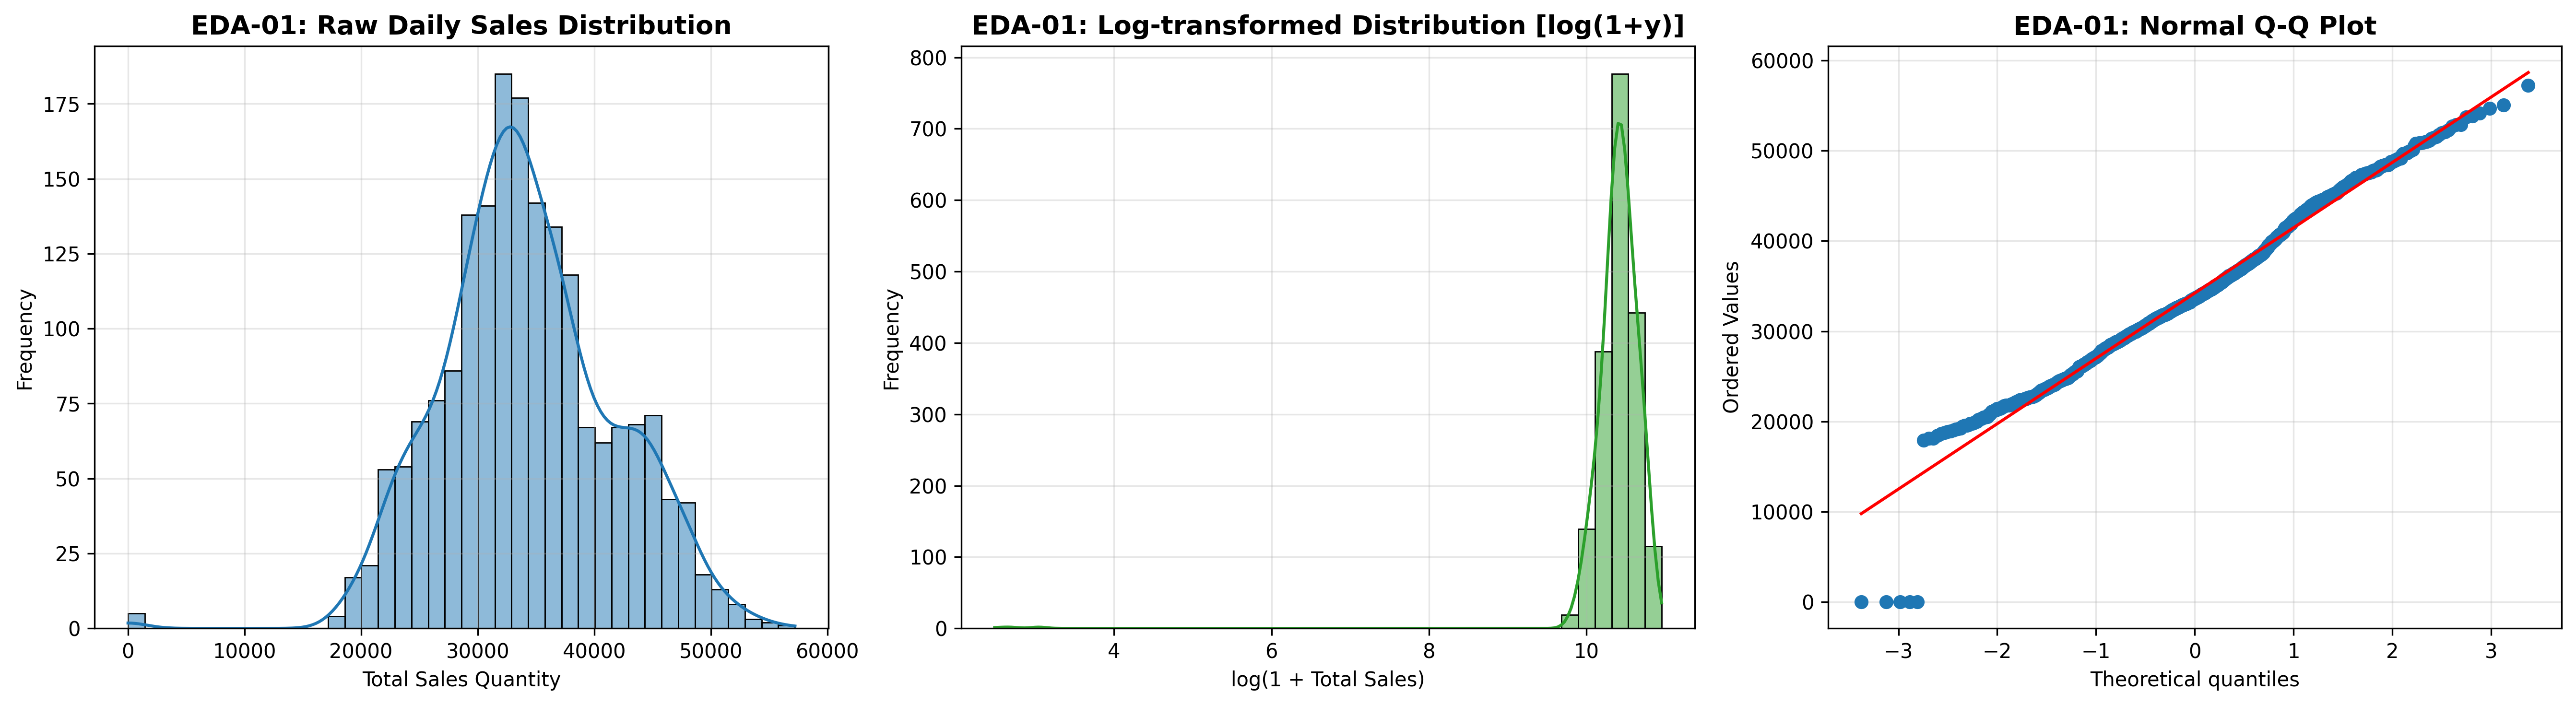

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(train_df['total_sales'], kde=True, ax=axes[0], color='#1f77b4', bins=40)
axes[0].set_title('EDA-01: Raw Daily Sales Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total Sales Quantity')
axes[0].set_ylabel('Frequency')

sns.histplot(np.log1p(train_df['total_sales']), kde=True, ax=axes[1], color='#2ca02c', bins=40)
axes[1].set_title('EDA-01: Log-transformed Distribution [log(1+y)]', fontsize=13, fontweight='bold')
axes[1].set_xlabel('log(1 + Total Sales)')
axes[1].set_ylabel('Frequency')

stats.probplot(train_df['total_sales'], dist='norm', plot=axes[2])
axes[2].set_title('EDA-01: Normal Q-Q Plot', fontsize=13, fontweight='bold')
axes[2].get_lines()[0].set_color('#1f77b4')
axes[2].get_lines()[1].set_color('red')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_01_sales_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


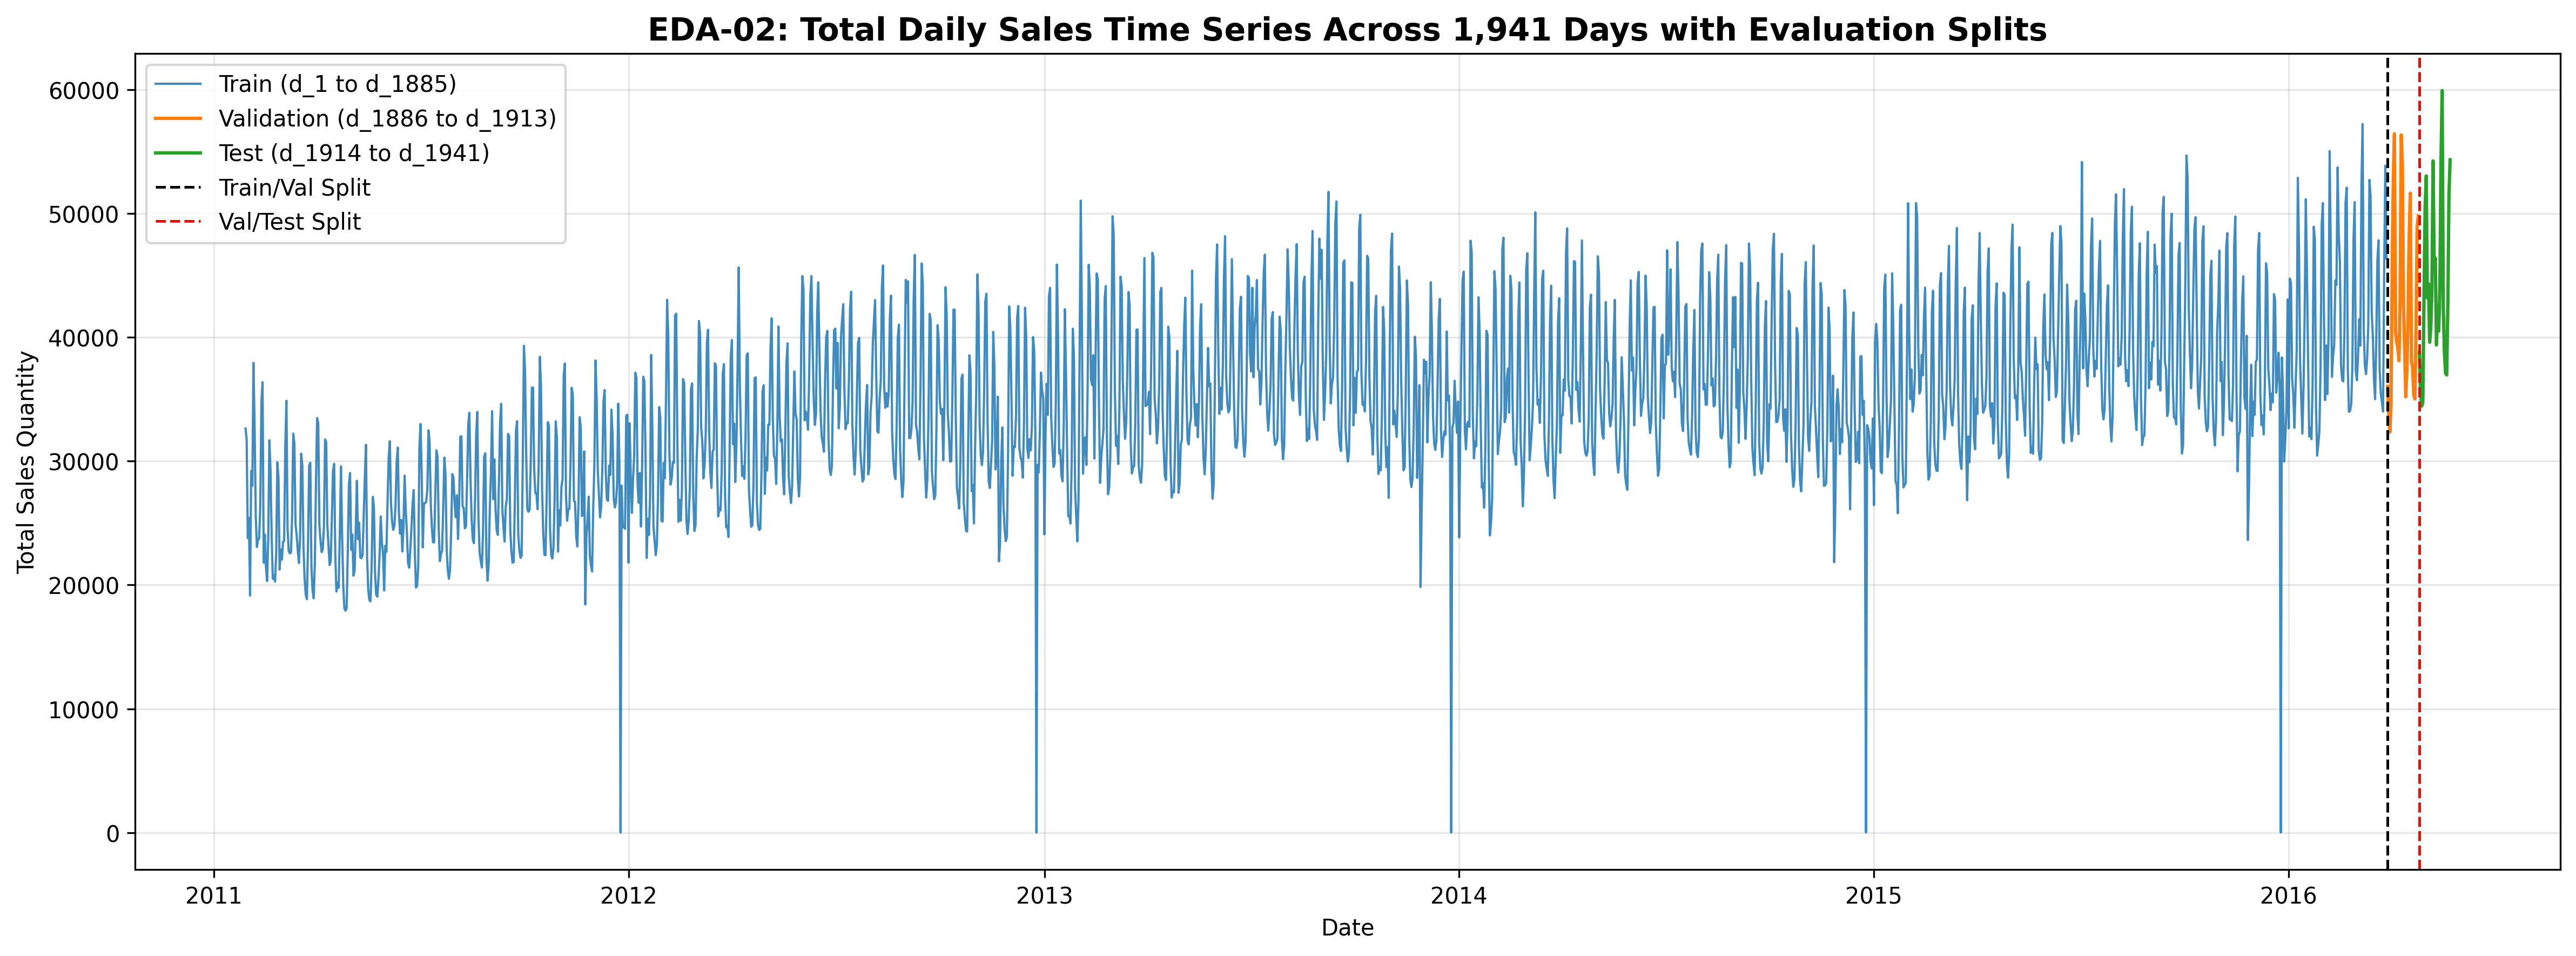

In [11]:
plt.figure(figsize=(16, 6))
plt.plot(train_df['date'], train_df['total_sales'], label='Train (d_1 to d_1885)', color='#1f77b4', lw=1, alpha=0.85)
plt.plot(val_df['date'], val_df['total_sales'], label='Validation (d_1886 to d_1913)', color='#ff7f0e', lw=1.5)
plt.plot(test_df['date'], test_df['total_sales'], label='Test (d_1914 to d_1941)', color='#2ca02c', lw=1.5)

plt.axvline(val_df['date'].iloc[0], color='black', linestyle='--', lw=1.2, label='Train/Val Split')
plt.axvline(test_df['date'].iloc[0], color='red', linestyle='--', lw=1.2, label='Val/Test Split')

plt.title('EDA-02: Total Daily Sales Time Series Across 1,941 Days with Evaluation Splits', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Total Sales Quantity')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_02_longterm_trend_splits.png', dpi=300, bbox_inches='tight')
plt.show()


/tmp/ipykernel_450/1139068346.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_df, x='weekday', y='total_sales', order=day_order, palette=palette)


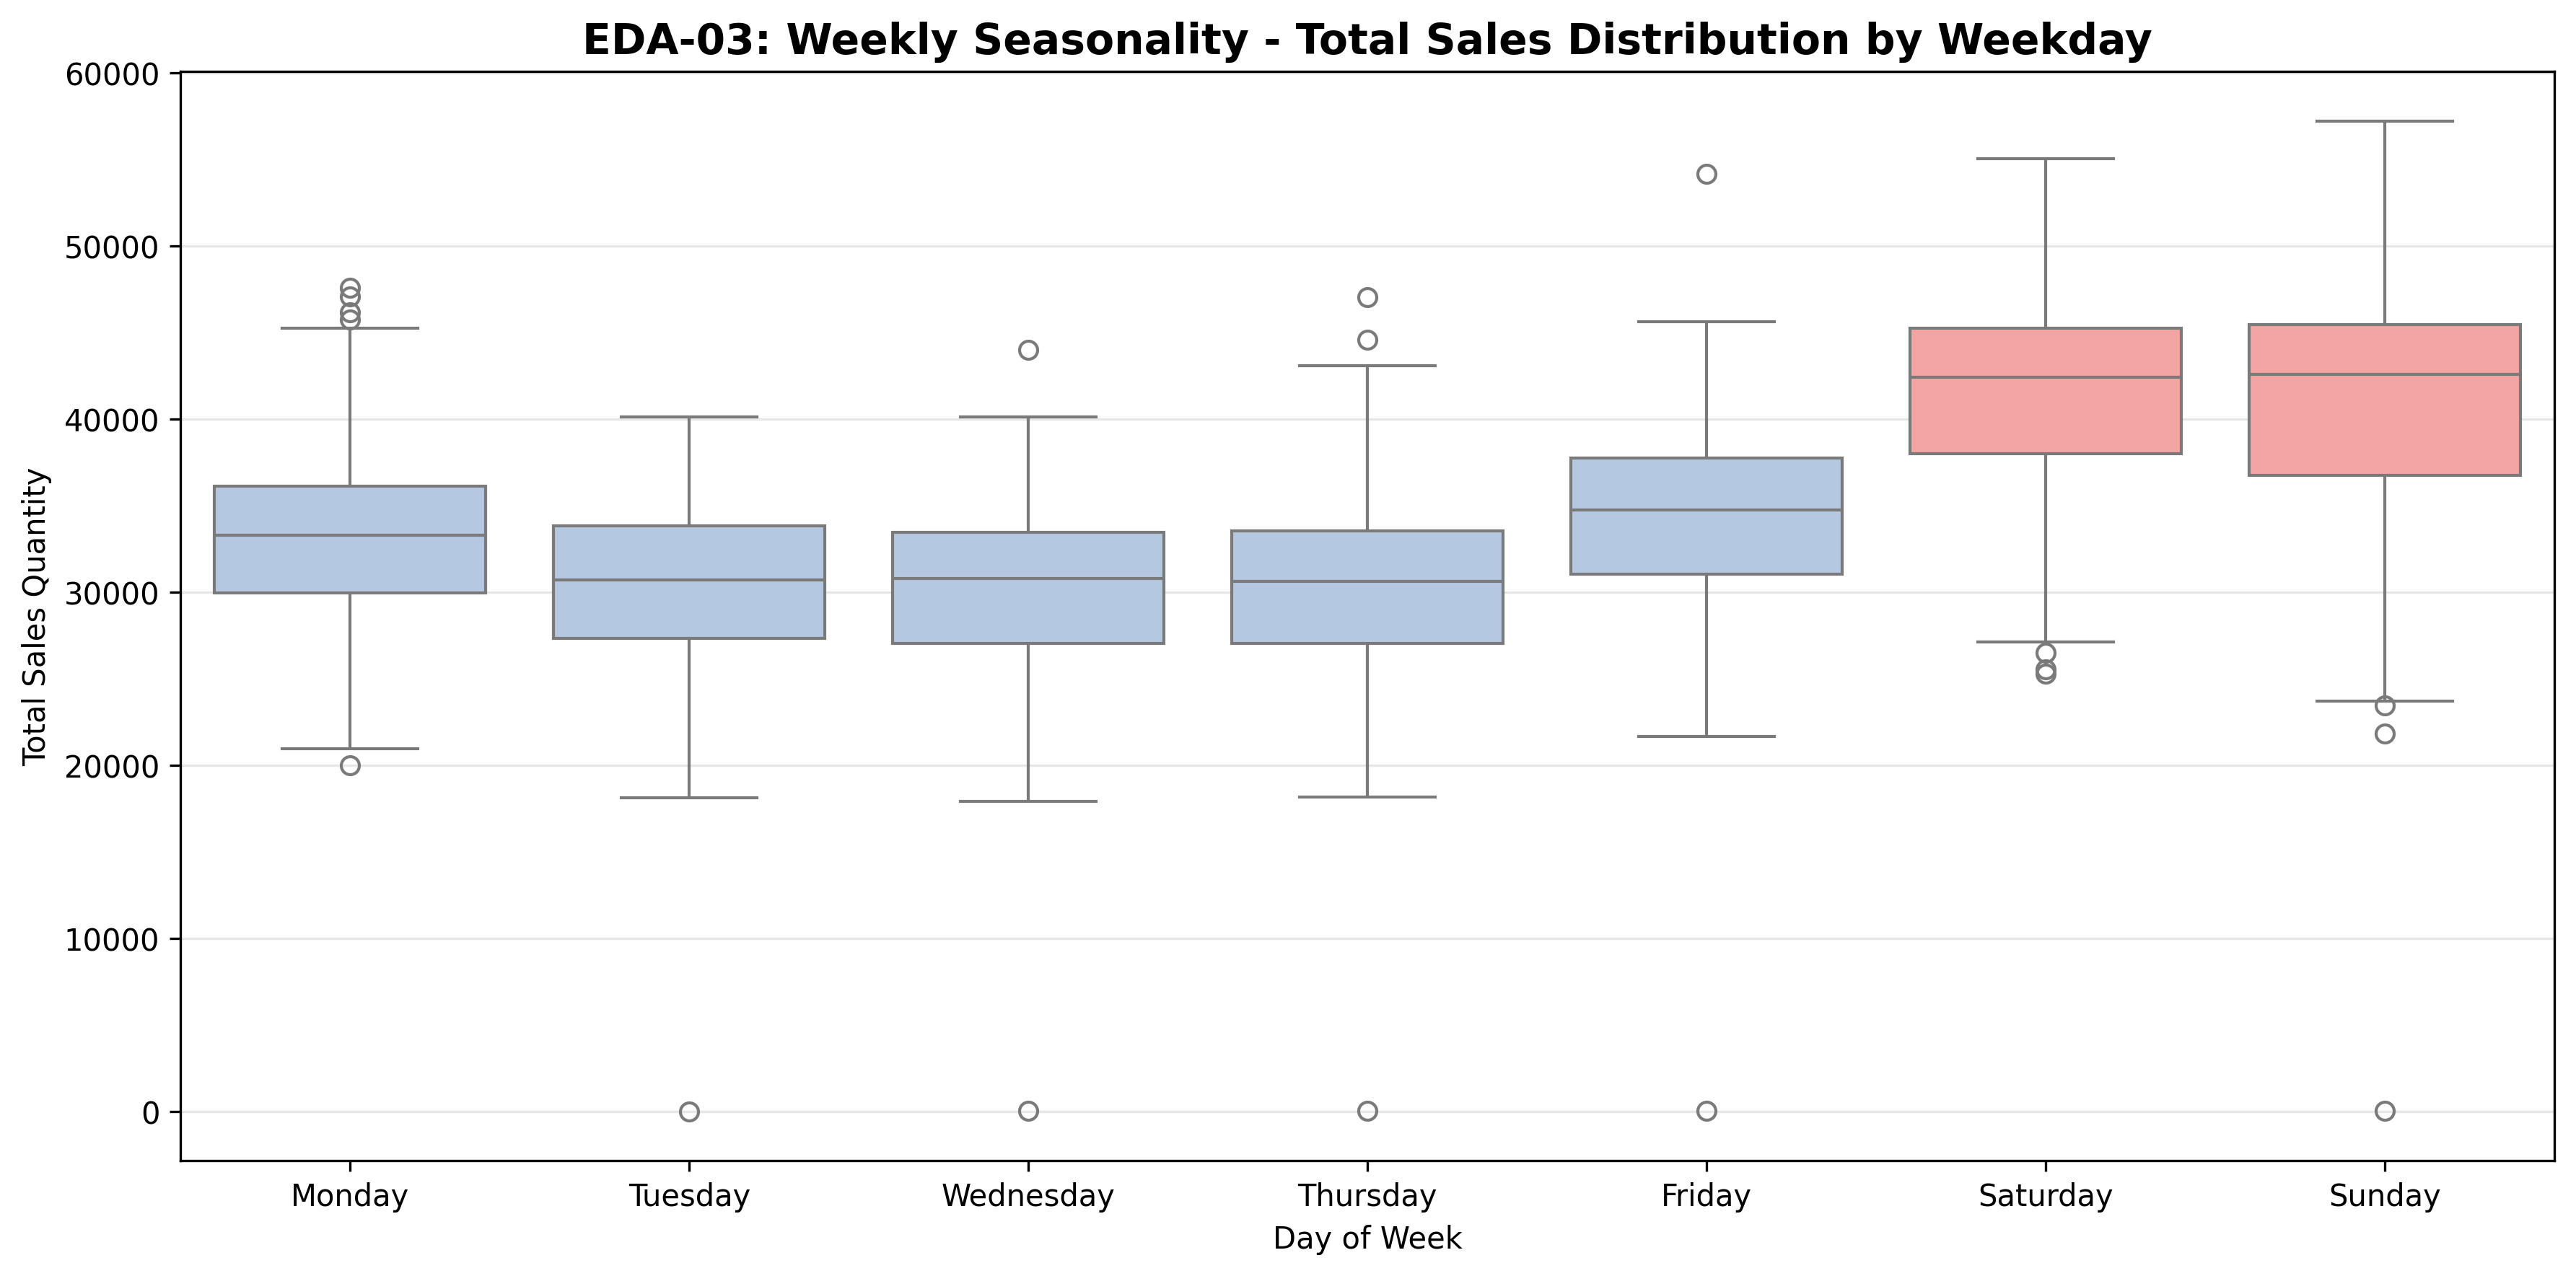

In [12]:
plt.figure(figsize=(12, 6))
palette = ['#aec7e8' if d not in ['Saturday', 'Sunday'] else '#ff9896' for d in day_order]
sns.boxplot(data=train_df, x='weekday', y='total_sales', order=day_order, palette=palette)
plt.title('EDA-03: Weekly Seasonality - Total Sales Distribution by Weekday', fontsize=14, fontweight='bold')
plt.xlabel('Day of Week')
plt.ylabel('Total Sales Quantity')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_03_weekly_seasonality.png', dpi=300, bbox_inches='tight')
plt.show()


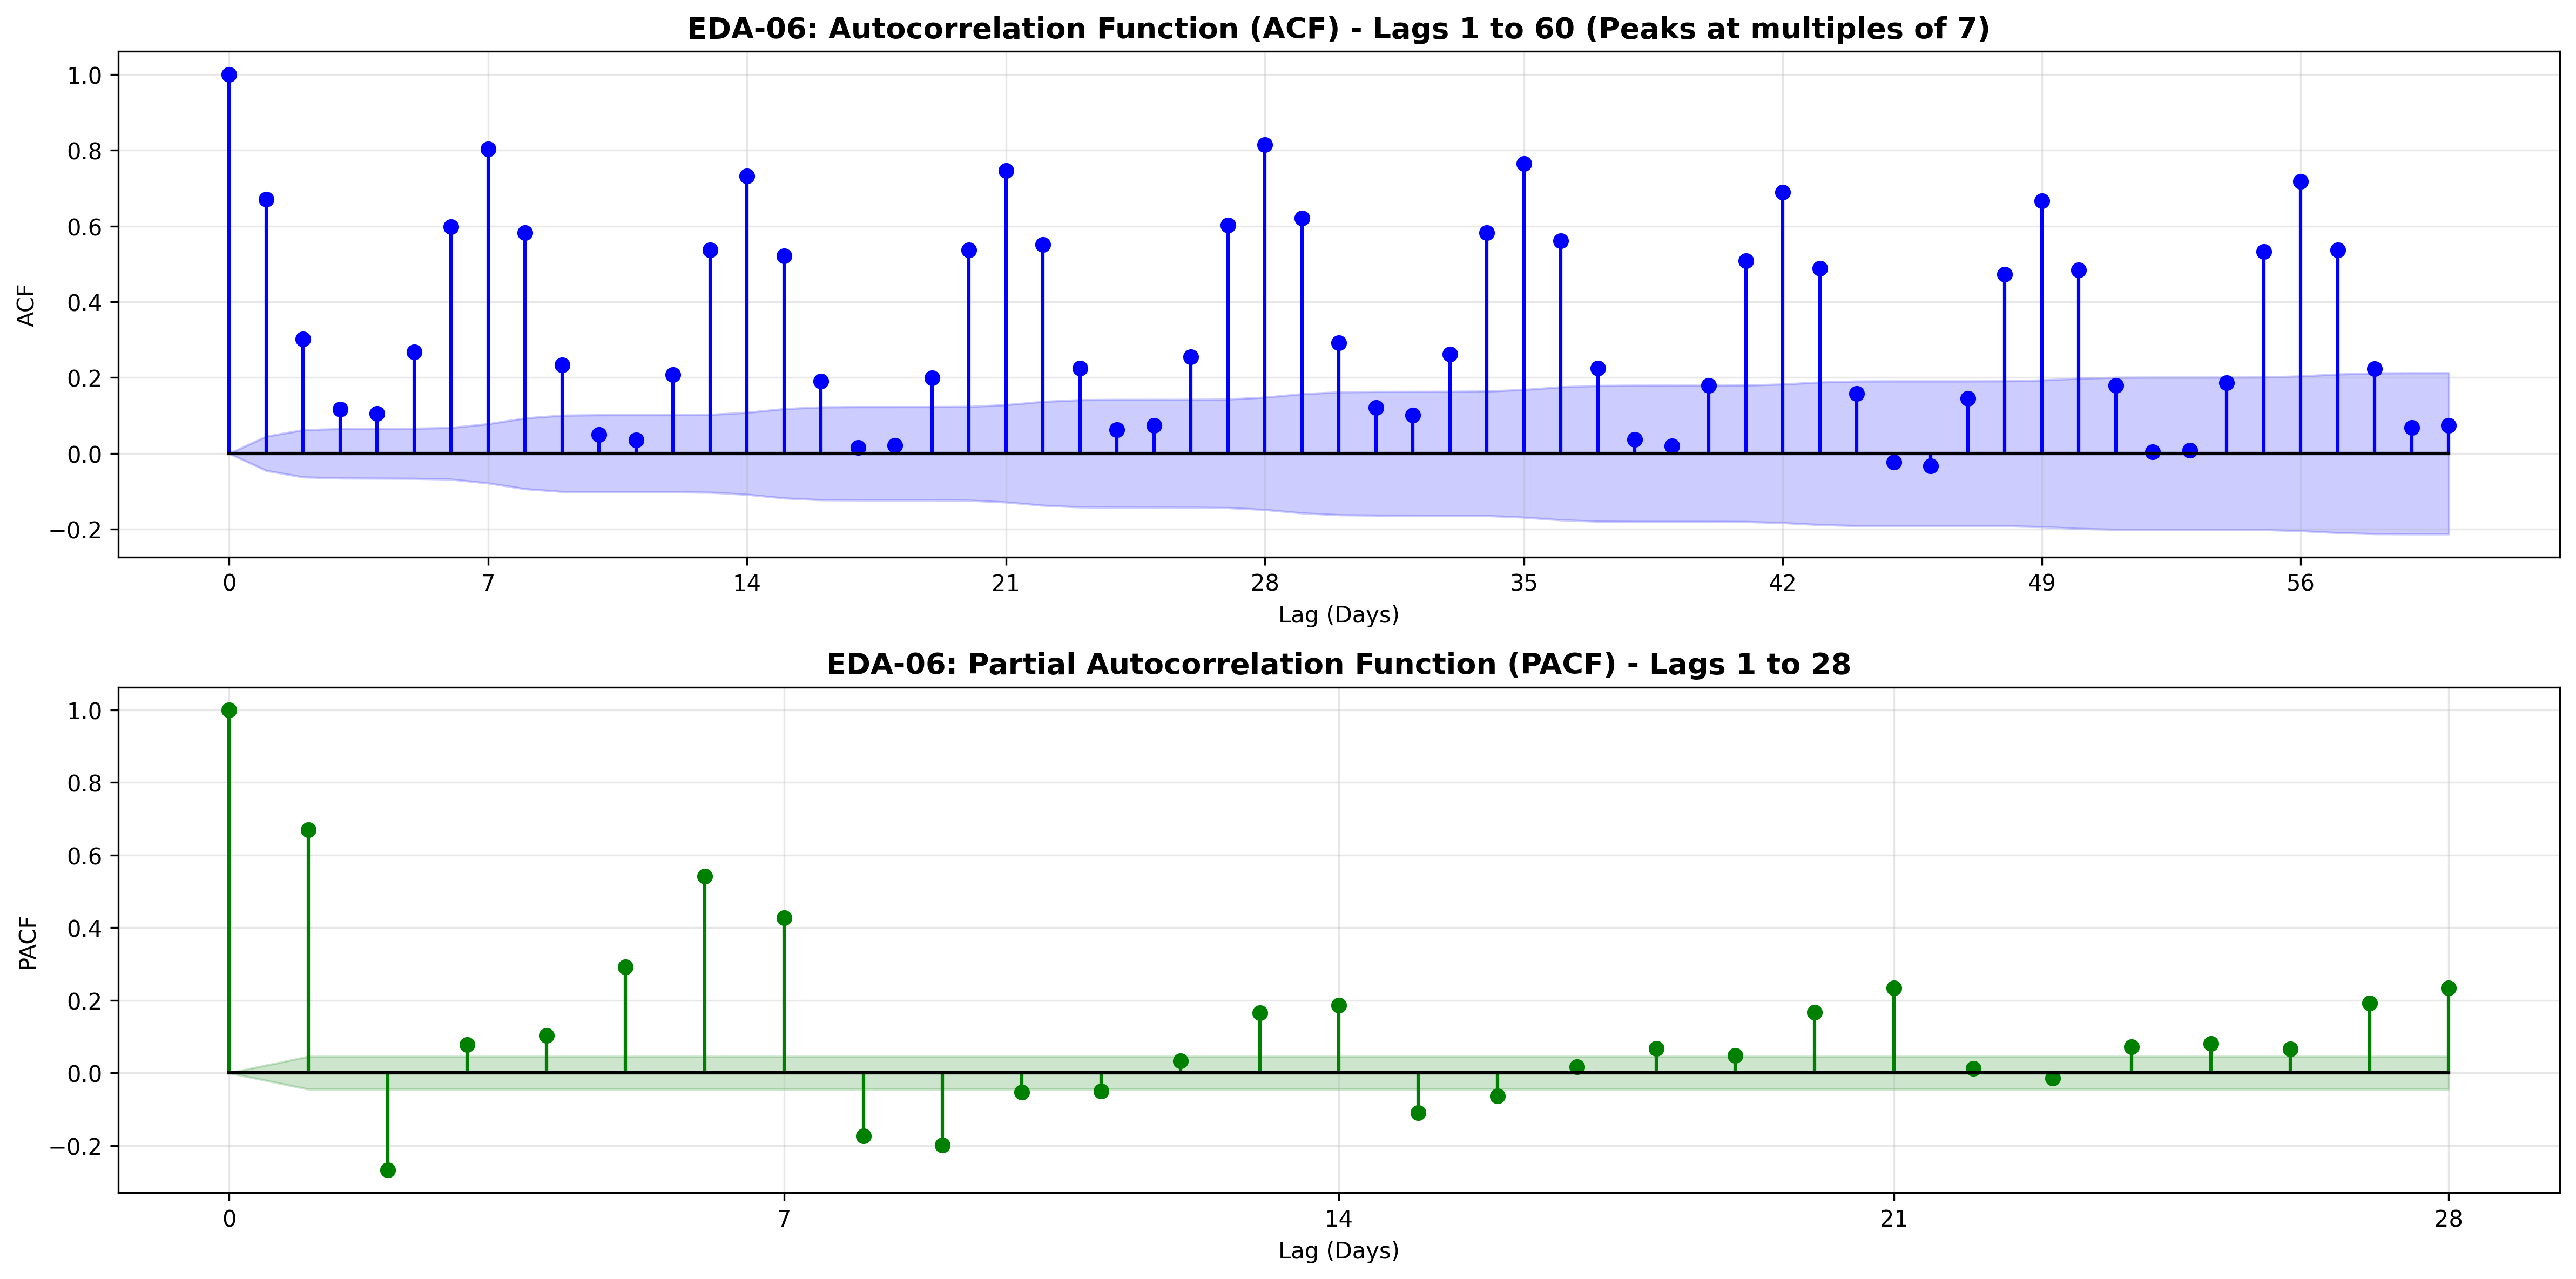

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=False)

lags_60 = range(len(acf_vals))
axes[0].stem(lags_60, acf_vals, linefmt='b-', markerfmt='bo', basefmt='k-')
axes[0].fill_between(lags_60, acf_conf[:, 0] - acf_vals, acf_conf[:, 1] - acf_vals, alpha=0.2, color='blue')
axes[0].set_title('EDA-06: Autocorrelation Function (ACF) - Lags 1 to 60 (Peaks at multiples of 7)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Lag (Days)')
axes[0].set_ylabel('ACF')
axes[0].set_xticks(range(0, 61, 7))

lags_28 = range(len(pacf_vals))
axes[1].stem(lags_28, pacf_vals, linefmt='g-', markerfmt='go', basefmt='k-')
axes[1].fill_between(lags_28, pacf_conf[:, 0] - pacf_vals, pacf_conf[:, 1] - pacf_vals, alpha=0.2, color='green')
axes[1].set_title('EDA-06: Partial Autocorrelation Function (PACF) - Lags 1 to 28', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Lag (Days)')
axes[1].set_ylabel('PACF')
axes[1].set_xticks(range(0, 29, 7))

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_04_acf_pacf.png', dpi=300, bbox_inches='tight')
plt.show()


/tmp/ipykernel_450/2965395317.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_df, x=col, y='total_sales', ax=axes[idx], palette=['#9ecae1', '#fa9fb5'])
/tmp/ipykernel_450/2965395317.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_xticklabels(['0 (Inactive)', '1 (Active)'])
/tmp/ipykernel_450/2965395317.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_df, x=col, y='total_sales', ax=axes[idx], palette=['#9ecae1', '#fa9fb5'])
/tmp/ipykernel_450/2965395317.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() o

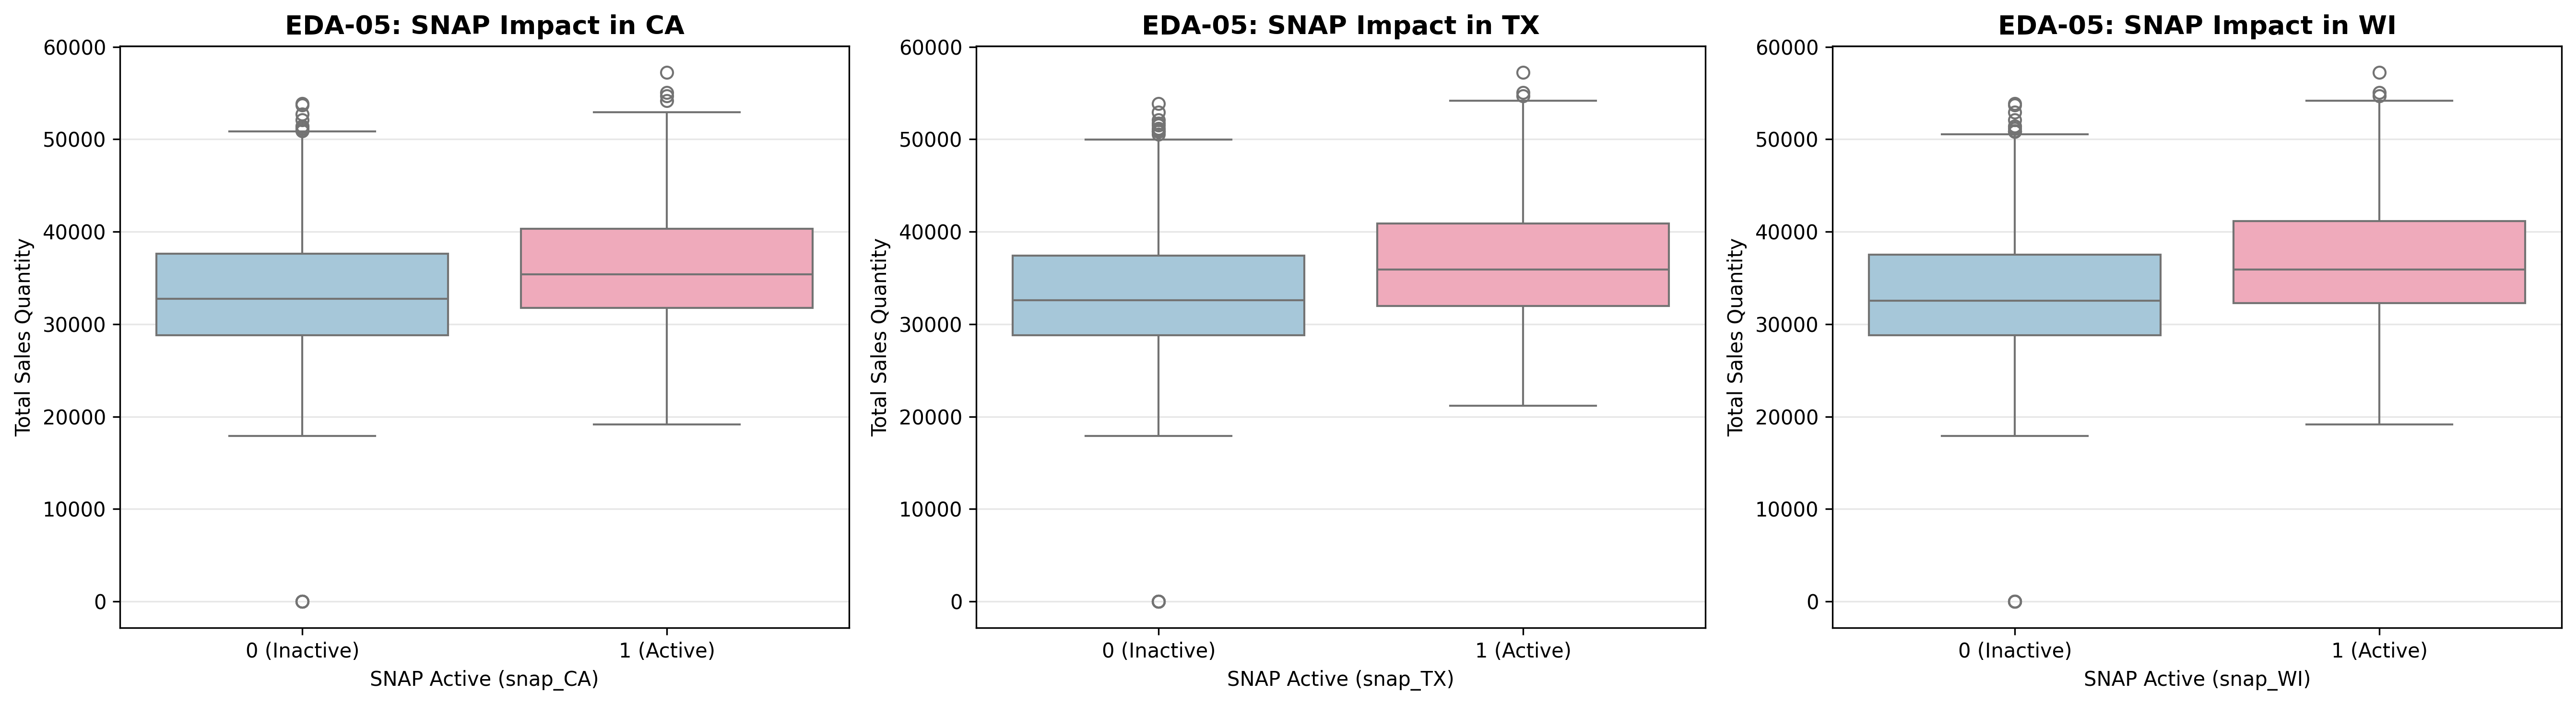

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, st in enumerate(['CA', 'TX', 'WI']):
    col = f'snap_{st}'
    sns.boxplot(data=train_df, x=col, y='total_sales', ax=axes[idx], palette=['#9ecae1', '#fa9fb5'])
    axes[idx].set_title(f'EDA-05: SNAP Impact in {st}', fontsize=13, fontweight='bold')
    axes[idx].set_xlabel(f'SNAP Active ({col})')
    axes[idx].set_ylabel('Total Sales Quantity')
    axes[idx].set_xticklabels(['0 (Inactive)', '1 (Active)'])

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_05_snap_impact.png', dpi=300, bbox_inches='tight')
plt.show()


/tmp/ipykernel_450/1909741743.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=full_df, x='split', y='total_sales', order=['Train', 'Val', 'Test'], ax=axes[0], palette=['#1f77b4', '#ff7f0e', '#2ca02c'])


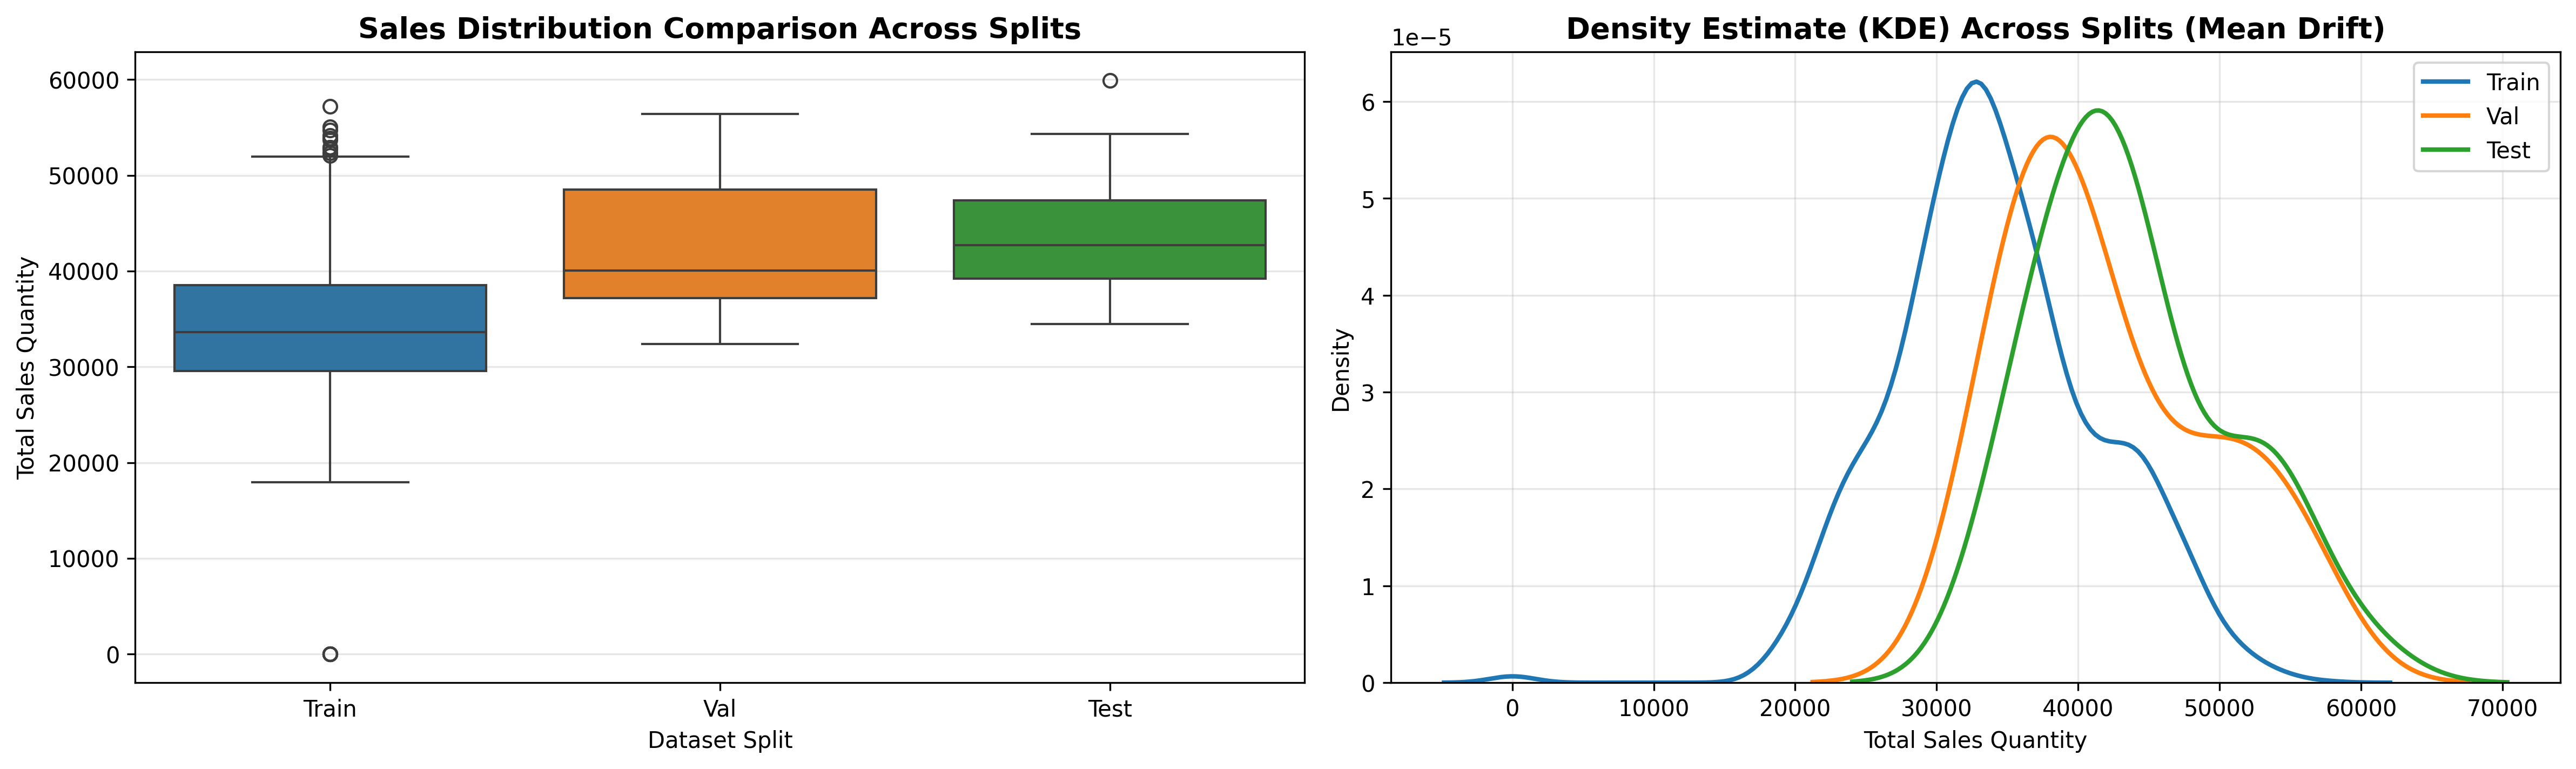

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=full_df, x='split', y='total_sales', order=['Train', 'Val', 'Test'], ax=axes[0], palette=['#1f77b4', '#ff7f0e', '#2ca02c'])
axes[0].set_title('Sales Distribution Comparison Across Splits', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Dataset Split')
axes[0].set_ylabel('Total Sales Quantity')

for sp, color in [('Train', '#1f77b4'), ('Val', '#ff7f0e'), ('Test', '#2ca02c')]:
    sns.kdeplot(full_df[full_df['split'] == sp]['total_sales'], ax=axes[1], label=sp, color=color, lw=2)
axes[1].set_title('Density Estimate (KDE) Across Splits (Mean Drift)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Total Sales Quantity')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_06_train_val_test_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


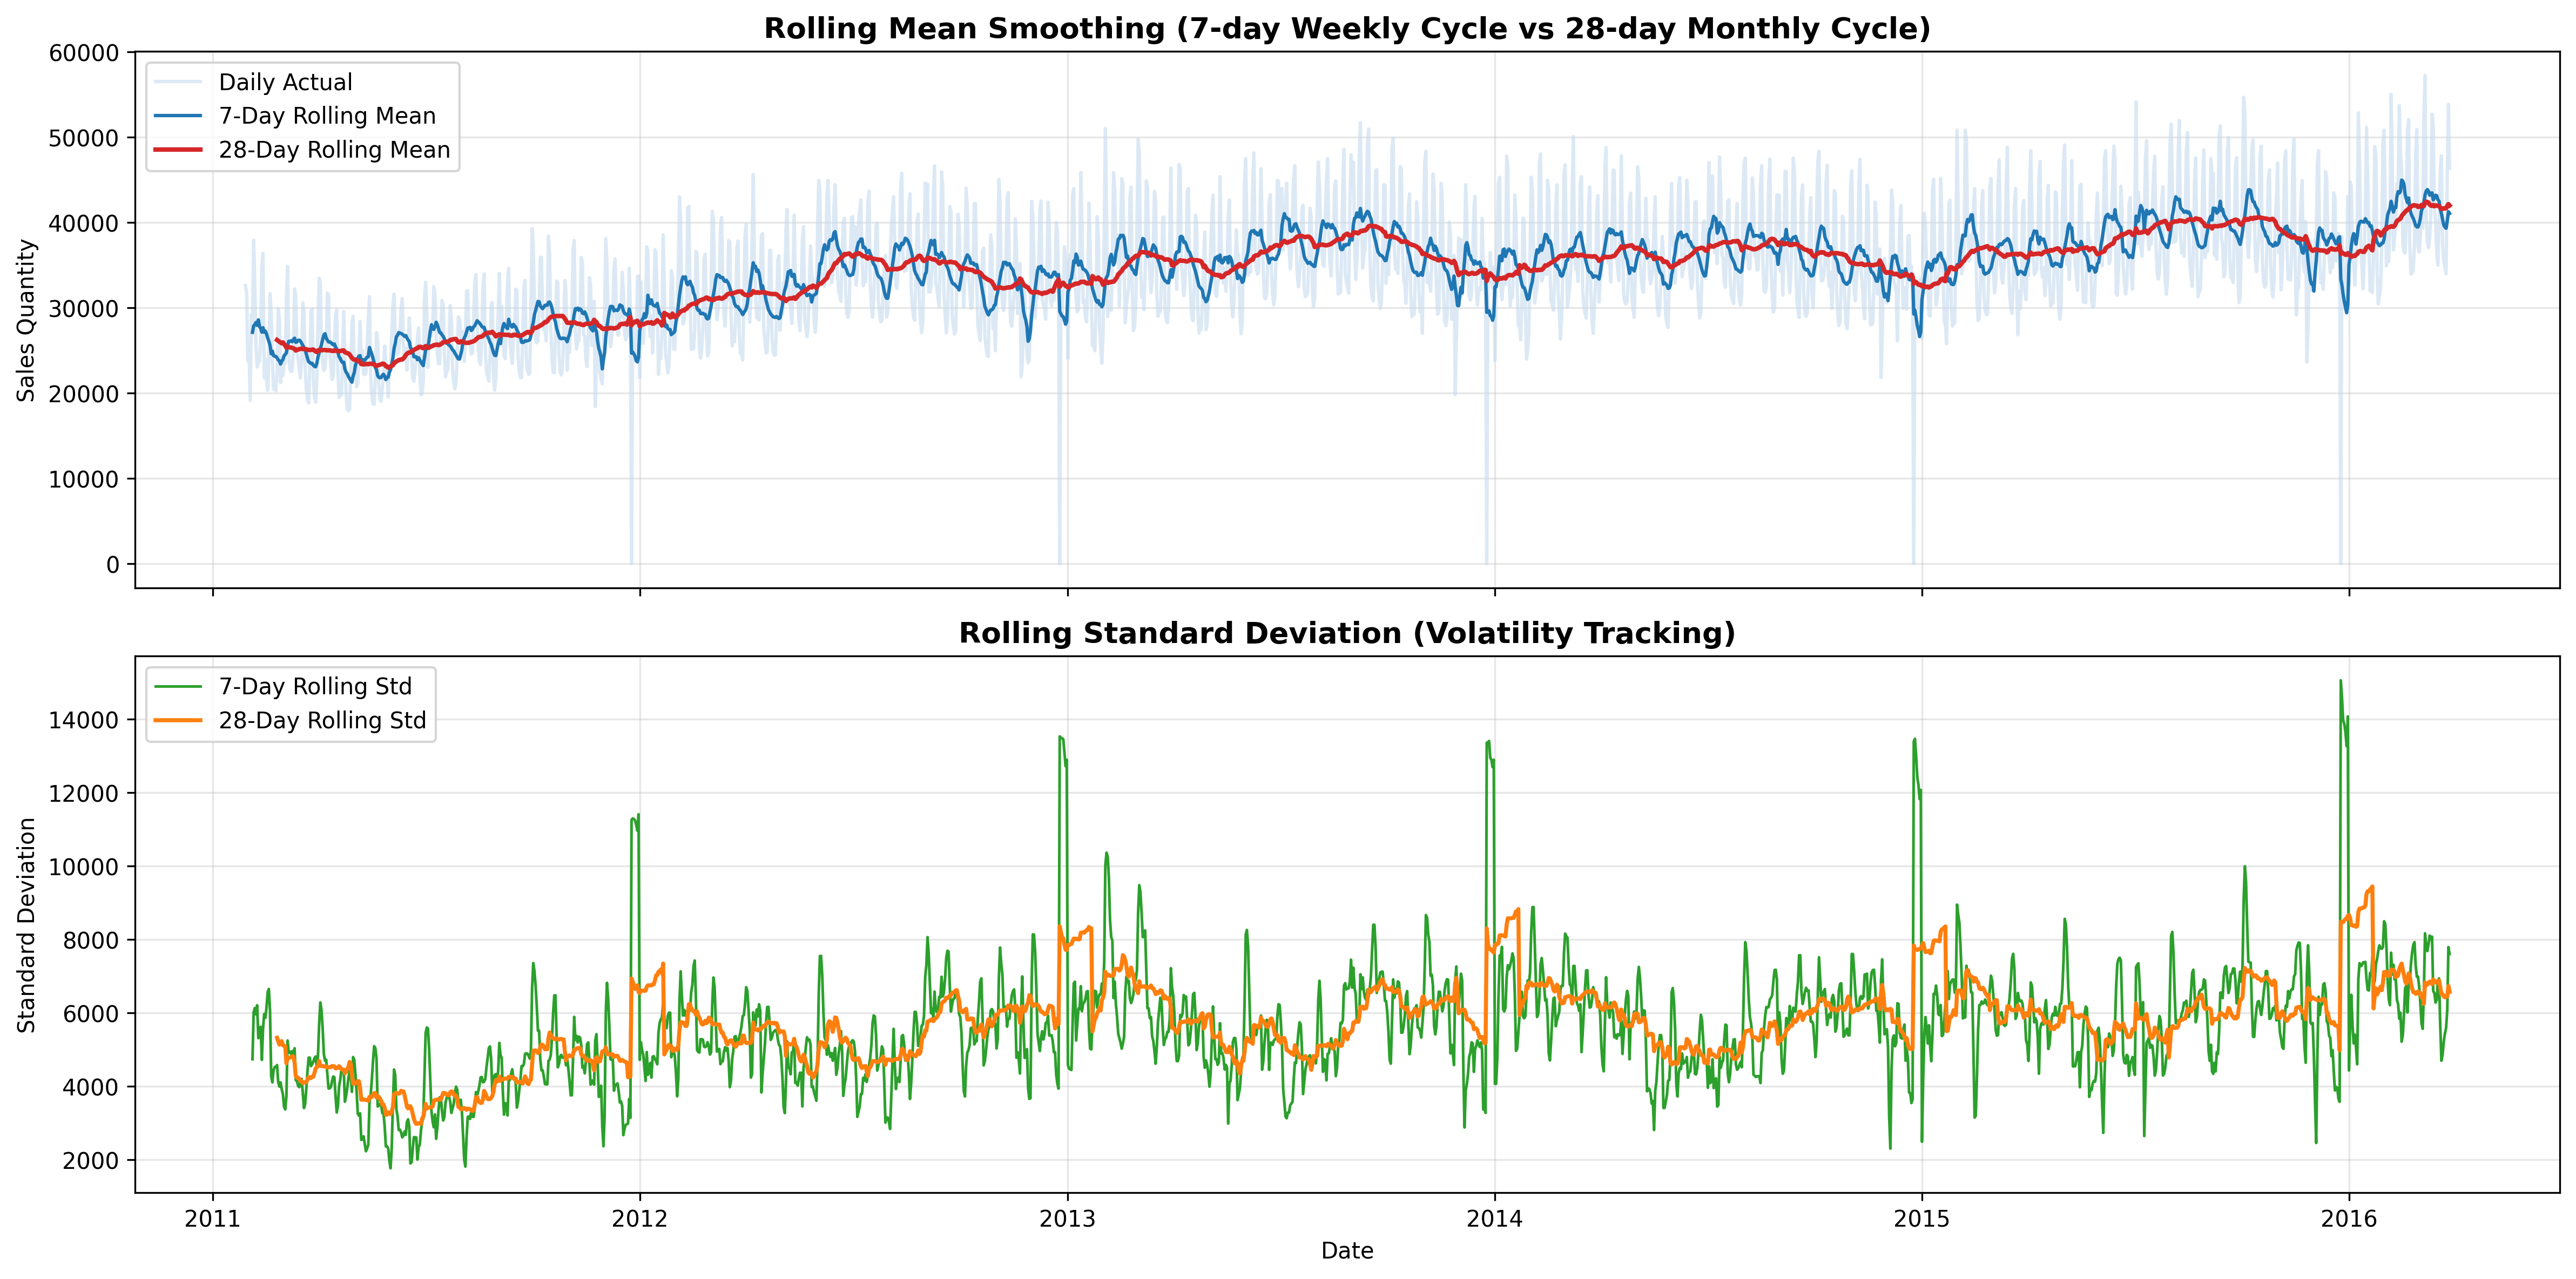

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

axes[0].plot(train_df['date'], train_df['total_sales'], color='#c6dbef', alpha=0.6, label='Daily Actual')
axes[0].plot(train_df['date'], train_df['rolling_mean_7'], color='#1f77b4', lw=1.5, label='7-Day Rolling Mean')
axes[0].plot(train_df['date'], train_df['rolling_mean_28'], color='#d62728', lw=2, label='28-Day Rolling Mean')
axes[0].set_title('Rolling Mean Smoothing (7-day Weekly Cycle vs 28-day Monthly Cycle)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sales Quantity')
axes[0].legend(loc='upper left')

axes[1].plot(train_df['date'], train_df['rolling_std_7'], color='#2ca02c', lw=1.2, label='7-Day Rolling Std')
axes[1].plot(train_df['date'], train_df['rolling_std_28'], color='#ff7f0e', lw=1.8, label='28-Day Rolling Std')
axes[1].set_title('Rolling Standard Deviation (Volatility Tracking)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Standard Deviation')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_07_rolling_statistics.png', dpi=300, bbox_inches='tight')
plt.show()


/tmp/ipykernel_450/628815234.py:2: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomp = seasonal_decompose(ts_series, model='additive', period=7, extrapolate_trend='freq')


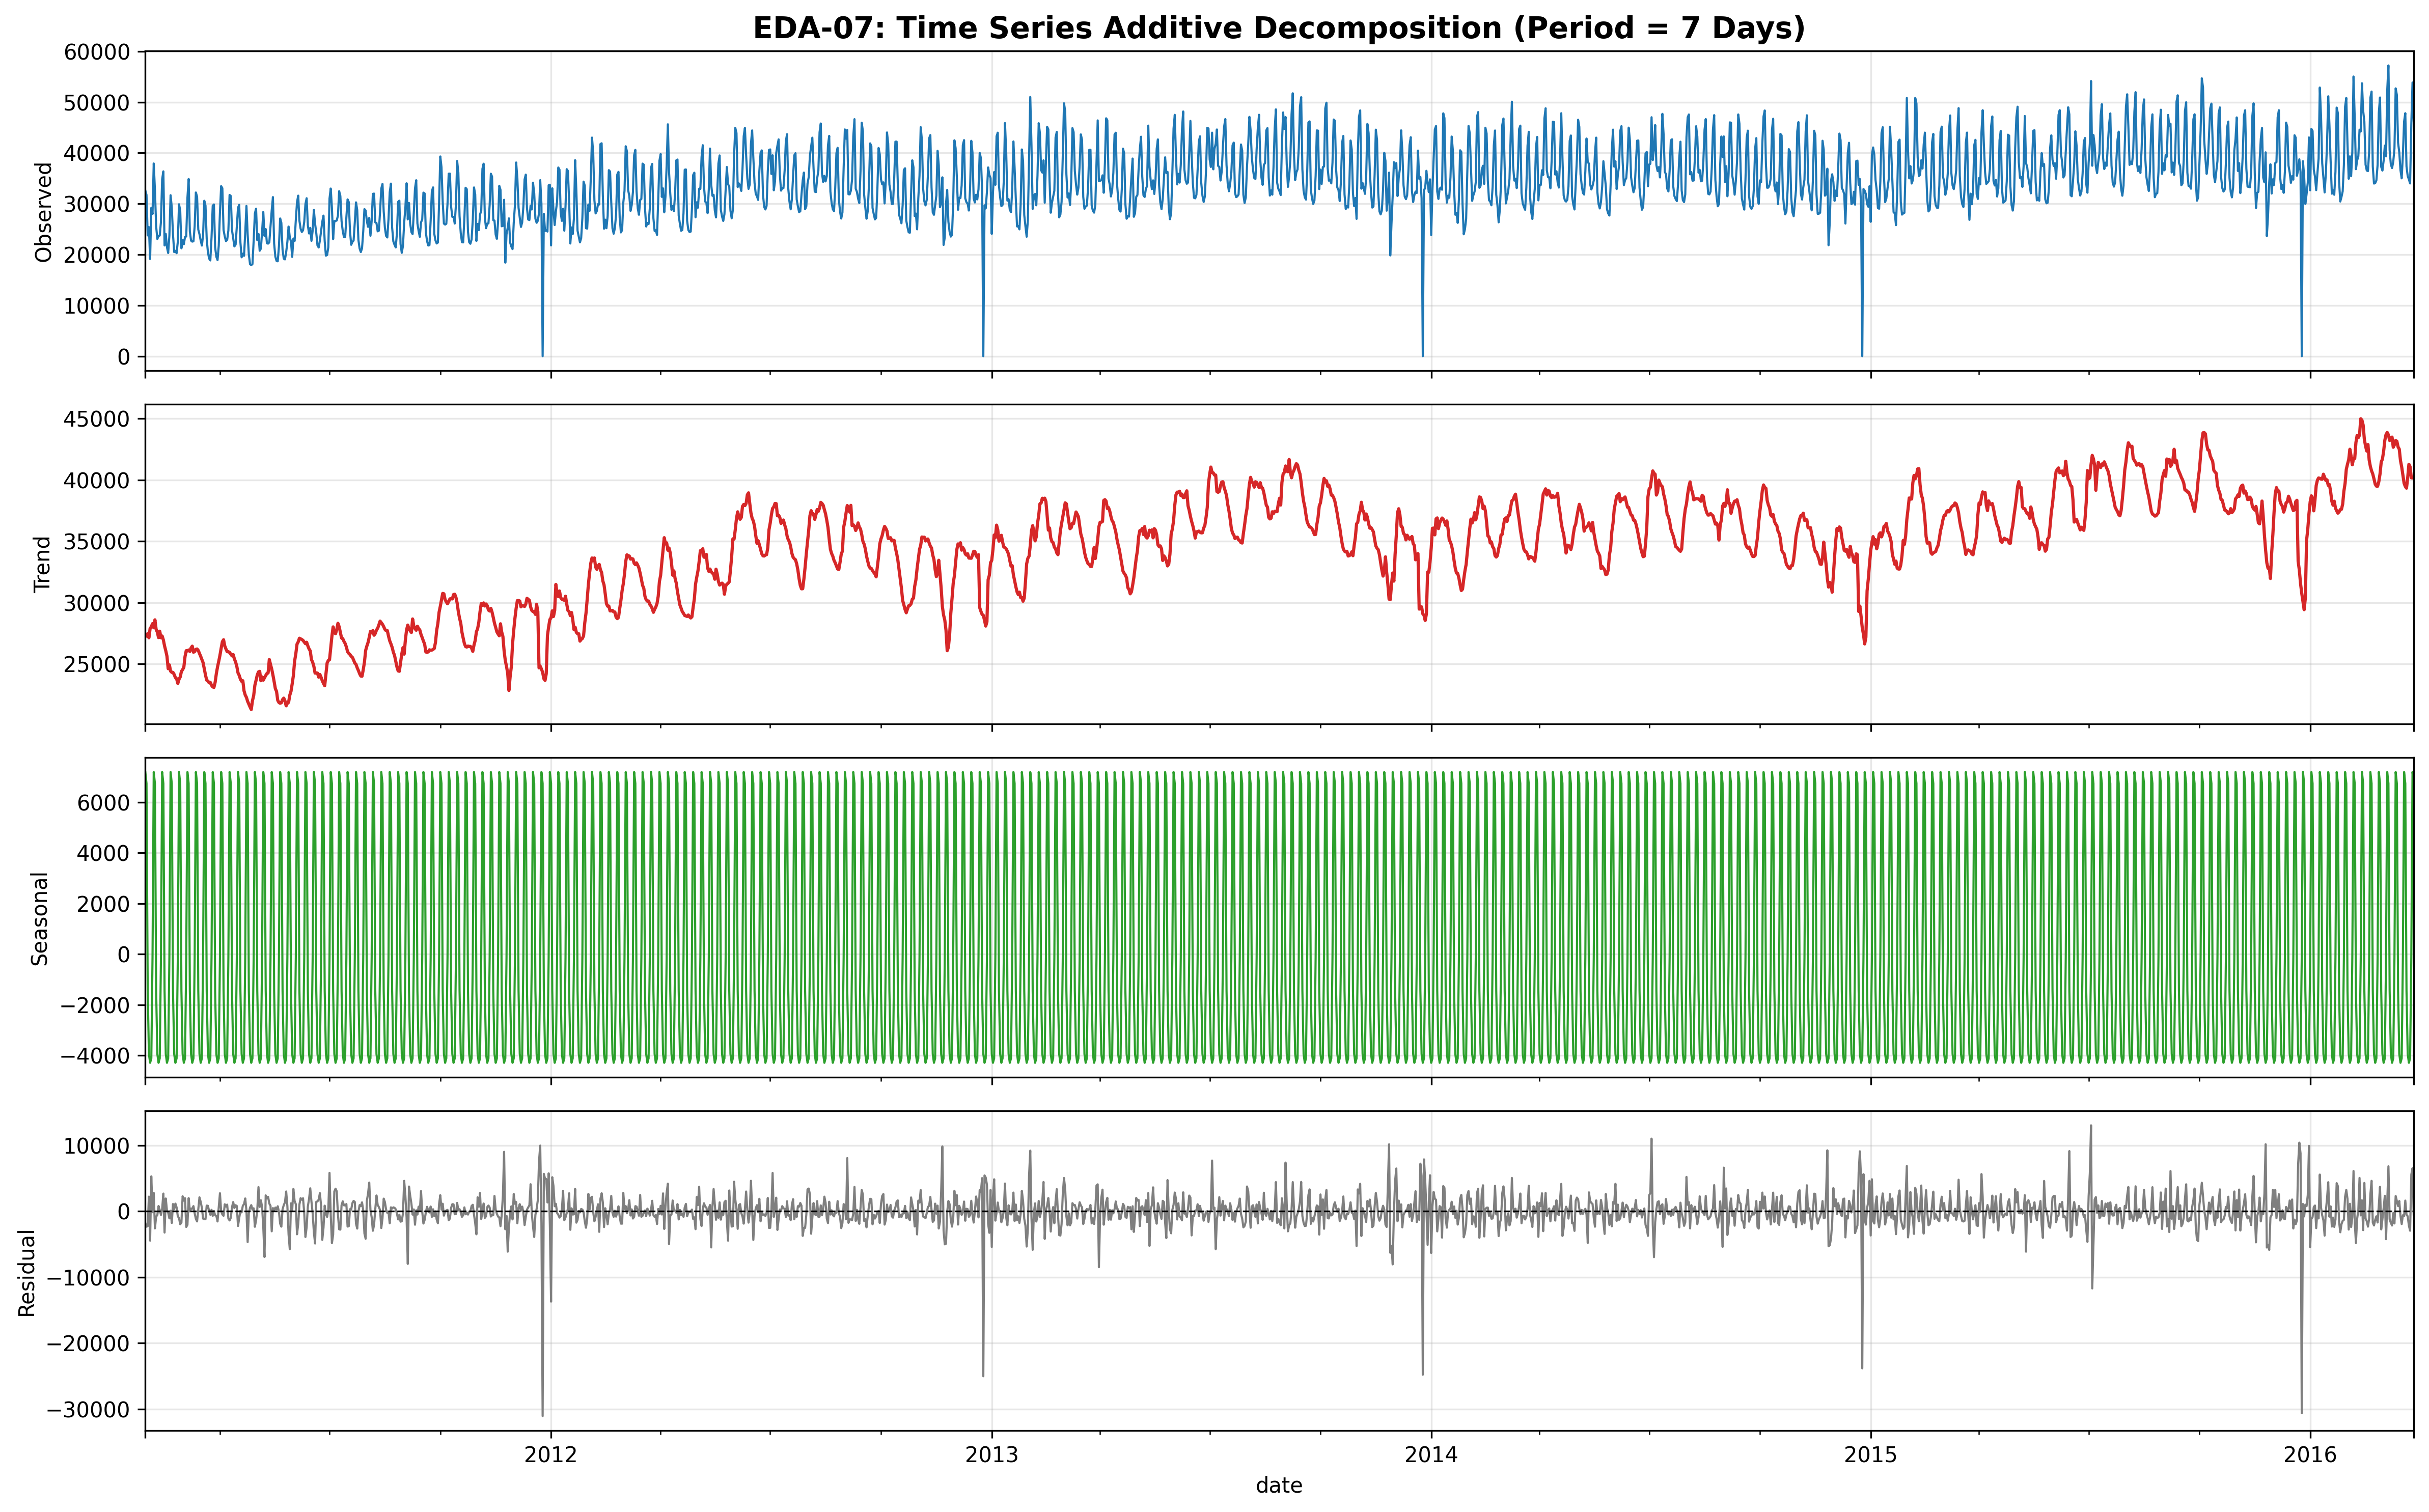

In [17]:
ts_series = train_df.set_index('date')['total_sales'].asfreq('D')
decomp = seasonal_decompose(ts_series, model='additive', period=7, extrapolate_trend='freq')

fig, axes = plt.subplots(4, 1, figsize=(16, 10), sharex=True)
decomp.observed.plot(ax=axes[0], color='#1f77b4', lw=1)
axes[0].set_ylabel('Observed')
axes[0].set_title('EDA-07: Time Series Additive Decomposition (Period = 7 Days)', fontsize=14, fontweight='bold')

decomp.trend.plot(ax=axes[1], color='#d62728', lw=1.5)
axes[1].set_ylabel('Trend')

decomp.seasonal.plot(ax=axes[2], color='#2ca02c', lw=1)
axes[2].set_ylabel('Seasonal')

decomp.resid.plot(ax=axes[3], color='#7f7f7f', lw=1)
axes[3].set_ylabel('Residual')
axes[3].axhline(0, color='black', linestyle='--', lw=0.8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_08_stl_decomposition.png', dpi=300, bbox_inches='tight')
plt.show()


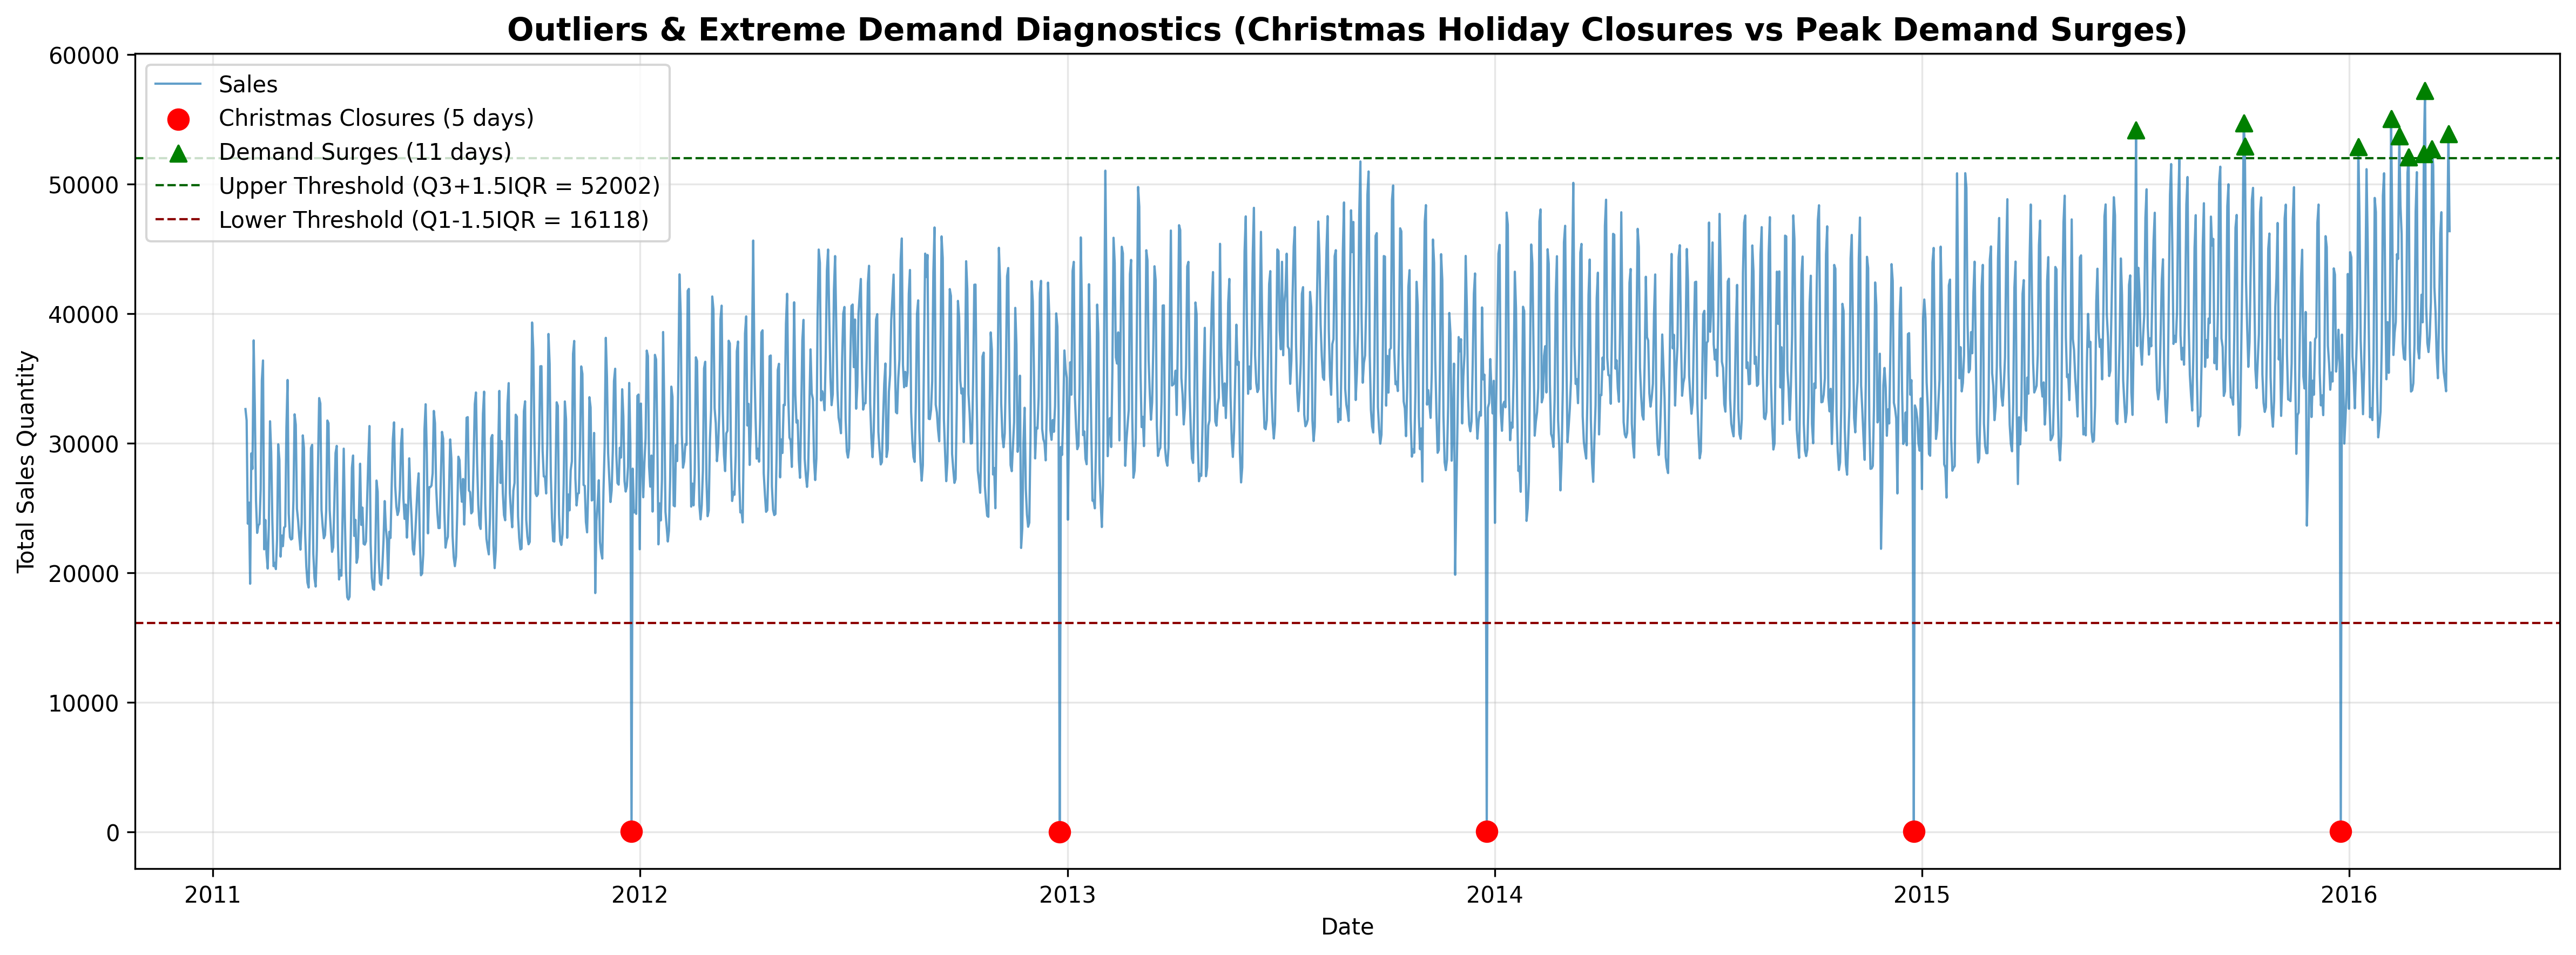

In [18]:
plt.figure(figsize=(16, 6))
plt.plot(train_df['date'], train_df['total_sales'], color='#1f77b4', lw=1, alpha=0.7, label='Sales')
plt.scatter(low_outliers['date'], low_outliers['total_sales'], color='red', s=80, zorder=5, label=f'Christmas Closures ({len(low_outliers)} days)')
plt.scatter(high_outliers['date'], high_outliers['total_sales'], color='green', s=50, marker='^', zorder=5, label=f'Demand Surges ({len(high_outliers)} days)')

plt.axhline(upper_bound, color='darkgreen', linestyle='--', lw=1, label=f'Upper Threshold (Q3+1.5IQR = {upper_bound:.0f})')
plt.axhline(lower_bound, color='darkred', linestyle='--', lw=1, label=f'Lower Threshold (Q1-1.5IQR = {lower_bound:.0f})')

plt.title('Outliers & Extreme Demand Diagnostics (Christmas Holiday Closures vs Peak Demand Surges)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Total Sales Quantity')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_09_outliers_christmas.png', dpi=300, bbox_inches='tight')
plt.show()
